In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name, low_memory=False)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Label"].value_counts())

print("\nMissing values:", df.isnull().sum().sum())
print("Infinite values:",
      np.isinf(df.select_dtypes(include=np.number)).sum().sum())

Saving CIC_IDS2017_Tuesday_Cleaned.csv to CIC_IDS2017_Tuesday_Cleaned.csv
Dataset shape: (421626, 79)

Class distribution:
Label
BENIGN         412476
FTP-Patator      5931
SSH-Patator      3219
Name: count, dtype: int64

Missing values: 0
Infinite values: 0


In [2]:
before = len(df)

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

if "Flow Duration" in df.columns:
    df = df[df["Flow Duration"] >= 0].copy()

print("Rows removed:", before - len(df))
print("Final shape:", df.shape)
print("\nClass distribution:")
print(df["Label"].value_counts())

Rows removed: 16
Final shape: (421610, 79)

Class distribution:
Label
BENIGN         412460
FTP-Patator      5931
SSH-Patator      3219
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Label"])
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X_train.shape[1])

Training records: 337288
Testing records: 84322
Number of features: 78


In [4]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [5]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, y_pred), 4))
print("Macro Precision:",
      round(precision_score(y_test, y_pred,
                            average="macro", zero_division=0), 4))
print("Macro Recall:",
      round(recall_score(y_test, y_pred,
                         average="macro", zero_division=0), 4))
print("Macro F1-score:",
      round(f1_score(y_test, y_pred,
                     average="macro", zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 1.0
Balanced Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     82492
 FTP-Patator       1.00      1.00      1.00      1186
 SSH-Patator       1.00      1.00      1.00       644

    accuracy                           1.00     84322
   macro avg       1.00      1.00      1.00     84322
weighted avg       1.00      1.00      1.00     84322



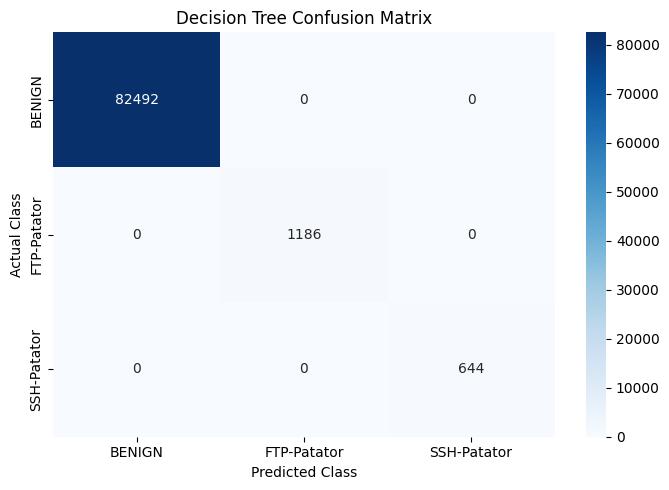

In [6]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

## Model Limitations

1. **Class imbalance:** The dataset contains substantially more benign traffic than attack traffic. Class weighting can help, but it does not guarantee good attack detection.

2. **Model simplicity:** A Decision Tree with a limited depth is a baseline model. Other algorithms may perform differently.

3. **Dataset limitations:** Performance on this dataset does not guarantee equivalent performance on real-world network traffic.

4. **Evaluation limitations:** A random train-test split may produce optimistic results when records share similar traffic patterns. Evaluation on separate days or scenarios would provide stronger evidence of generalization.

5. **Further improvements:** Future work could compare Random Forest and other classifiers, investigate feature importance, and evaluate performance on independently collected traffic.